# 05 · Controlled Kernel Experiment (main result)

**Question:** does kernel concentration predict QSVC performance, and how much does it depend on the encoding and preprocessing?

**Design:** everything is fixed except the encoding and the preprocessing.

| Fixed | Varied |
| --- | --- |
| Jets, event-level split (seed 42), test set | Encoding: amplitude (2 qubits, zero-padded), angle (3 qubits, RY) |
| Inputs: `QG_mult`, `QG_ptD`, `QG_axis2` (CMS QGL inputs) | Preprocessing: raw, StandardScaler, RobustScaler + Yeo–Johnson, min-max (all fitted on the training subsample) |
| Model: SVC with precomputed quantum kernel, C = 1 | Training subsample: balanced 400 jets, seeds 0–4 |
| | Preprocessing also includes min-max to [0, 1] (equal scales, positive values) |

Each configuration is evaluated twice:
- **exact kernel** (noiseless statevector overlaps), and
- **finite-shot kernel**: every entry replaced by a binomial estimate with 1000 shots, as it would be measured on hardware.

Concentration (Thanasilp et al. 2024): mean and **variance of the off-diagonal kernel values**. A concentrated kernel has variance → 0 (all jets look alike).

Output: `results/kernel_experiment.json`, Fig. 7 (main figure).

In [1]:
import sys
sys.path.insert(0, "src")

import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from sklearn.metrics import roc_auc_score
from sklearn.svm import SVC

from jet_data import load_jets, select_quark_gluon, feature_matrix, event_level_split, balanced_subsample, BOOKKEEPING
from kernels import (PREPROCESSING, KERNELS, preprocess, amplitude_states, shot_noise,
                     concentration, effective_rank, entanglement_entropy_2q)
from figure_style import set_style, save, COLORS

set_style()
SEED = 42
SEEDS = [0, 1, 2, 3, 4]
N_PER_CLASS = 200
SHOTS = 1000
FEATURES = ("QG_mult", "QG_ptD", "QG_axis2")
RESULTS = Path("results"); RESULTS.mkdir(exist_ok=True)
baselines = json.load(open(RESULTS / "baselines.json"))     # from notebook 04

raw = load_jets(features=FEATURES, extra=BOOKKEEPING)
jets = select_quark_gluon(raw, require_loose_id=True)
y = jets["label"]
X = feature_matrix(jets, features=FEATURES)
train, test = event_level_split(jets, test_fraction=0.3, seed=SEED)
print(f"train {int(train.sum())}, test {int(test.sum())}")

train 9729, test 4183


## 1. Cross-check: closed-form kernels vs Qiskit circuits

The experiment uses closed-form overlaps (fast). This cell builds the actual Qiskit circuits for 5 jets and compares.

In [2]:
from qiskit.quantum_info import Statevector
from quantum_encodings import amplitude_encoding_circuit, angle_encoding_circuit

idx = balanced_subsample(y, train, N_PER_CLASS, seed=0)
A = preprocess("standard", X[idx])[:5]
for name, circuit in (("amplitude", amplitude_encoding_circuit), ("angle", angle_encoding_circuit)):
    psi = [Statevector(circuit(a)).data for a in A]
    K_qiskit = np.array([[abs(np.vdot(p, q))**2 for q in psi] for p in psi])
    K_closed = KERNELS[name](A, A)
    print(f"{name:9s} max |Qiskit - closed form| = {np.max(np.abs(K_qiskit - K_closed)):.1e}")

amplitude max |Qiskit - closed form| = 1.4e-15
angle     max |Qiskit - closed form| = 6.7e-16


## 2. Run the experiment

2 encodings × 4 preprocessings × 5 seeds × (exact, 1000 shots). Takes about a minute.

In [3]:
records = []
for enc, kernel in KERNELS.items():
    for prep in PREPROCESSING:
        for s in SEEDS:
            idx = balanced_subsample(y, train, N_PER_CLASS, seed=s)
            A, T = preprocess(prep, X[idx], X[test])
            K_tr, K_te = kernel(A, A), kernel(T, A)

            mean_k, var_k = concentration(K_tr)
            rec = {"encoding": enc, "prep": prep, "seed": s,
                   "kernel_mean": float(mean_k), "kernel_var": float(var_k),
                   "eff_rank": effective_rank(K_tr)}
            if enc == "amplitude":
                rec["entanglement"] = float(entanglement_entropy_2q(amplitude_states(A)).mean())

            svc = SVC(kernel="precomputed", C=1.0).fit(K_tr, y[idx])
            rec["auc_exact"] = roc_auc_score(y[test], svc.decision_function(K_te))

            rng = np.random.default_rng(1000 + s)
            K_tr_s = shot_noise(K_tr, SHOTS, rng, symmetric=True)
            K_te_s = shot_noise(K_te, SHOTS, rng)
            svc = SVC(kernel="precomputed", C=1.0).fit(K_tr_s, y[idx])
            rec["auc_shots"] = roc_auc_score(y[test], svc.decision_function(K_te_s))
            records.append(rec)
    print(f"{enc} done")

json.dump({"shots": SHOTS, "n_per_class": N_PER_CLASS, "features": list(FEATURES), "records": records},
          open(RESULTS / "kernel_experiment.json", "w"), indent=2)
print("saved results/kernel_experiment.json")

amplitude done
angle done
saved results/kernel_experiment.json


## 3. Results table (mean ± std over 5 seeds)

In [4]:
def summarise(enc, prep, key):
    v = np.array([r[key] for r in records if r["encoding"] == enc and r["prep"] == prep])
    return v.mean(), v.std()

print(f"{'encoding':10s} {'prep':10s} {'K mean':>8s} {'K var':>10s} {'eff. rank':>9s} {'AUC exact':>14s} {'AUC 1000 shots':>15s}")
for enc in KERNELS:
    for prep in PREPROCESSING:
        km, _ = summarise(enc, prep, "kernel_mean")
        kv, _ = summarise(enc, prep, "kernel_var")
        er, _ = summarise(enc, prep, "eff_rank")
        ae, ae_s = summarise(enc, prep, "auc_exact")
        ash, ash_s = summarise(enc, prep, "auc_shots")
        print(f"{enc:10s} {prep:10s} {km:8.4f} {kv:10.2e} {er:9.2f} {ae:8.3f} ± {ae_s:.3f} {ash:9.3f} ± {ash_s:.3f}")

rbf = np.array(baselines["rbf_svm_sub_auc"]); bdt = np.array(baselines["bdt_sub_auc"])
print()
print(f"Classical, same 400-jet subsamples: RBF-SVM {rbf.mean():.3f} ± {rbf.std():.3f}, BDT {bdt.mean():.3f} ± {bdt.std():.3f}")
print(f"CMS QGL (full test set): {baselines['qgl_test_auc']:.3f}")
print()
for prep in PREPROCESSING:
    e, e_s = summarise("amplitude", prep, "entanglement")
    print(f"amplitude, {prep:10s}: mean entanglement entropy {e:.3f} ± {e_s:.3f} bits")

encoding   prep         K mean      K var eff. rank      AUC exact  AUC 1000 shots
amplitude  raw          0.9990   1.39e-05      1.01    0.699 ± 0.000     0.690 ± 0.004
amplitude  standard     0.4059   1.02e-01      4.61    0.614 ± 0.019     0.604 ± 0.012
amplitude  robust_yj    0.4496   1.09e-01      4.01    0.576 ± 0.023     0.572 ± 0.014
amplitude  minmax       0.6456   6.92e-02      2.68    0.800 ± 0.001     0.793 ± 0.002
angle      raw          0.4955   1.23e-01      2.97    0.741 ± 0.034     0.726 ± 0.026
angle      standard     0.3824   9.69e-02      6.62    0.778 ± 0.004     0.776 ± 0.002
angle      robust_yj    0.3507   8.93e-02      7.23    0.786 ± 0.003     0.782 ± 0.004
angle      minmax       0.9550   2.08e-03      1.25    0.794 ± 0.003     0.792 ± 0.003

Classical, same 400-jet subsamples: RBF-SVM 0.782 ± 0.004, BDT 0.746 ± 0.007
CMS QGL (full test set): 0.790

amplitude, raw       : mean entanglement entropy 0.000 ± 0.000 bits
amplitude, standard  : mean entanglement en

## 4. Main figure: concentration vs test AUC

One point per encoding × preprocessing (mean over 5 seeds, error bars = std).
Left: exact kernels. Right: the same kernels measured with 1000 shots per entry.
Reference lines: RBF-SVM on the same subsamples and the CMS likelihood.

saved figures/fig07_concentration_vs_auc.pdf and .png


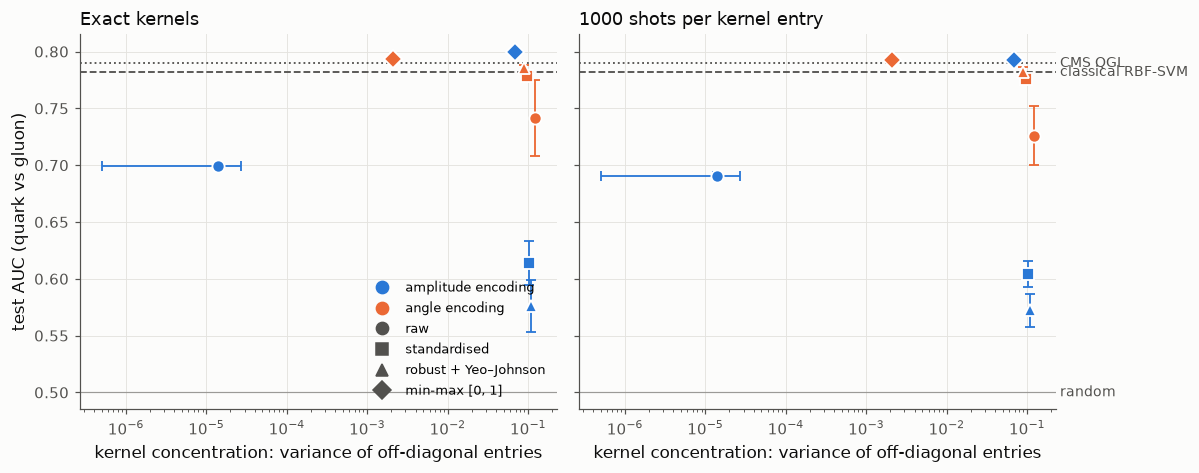

In [5]:
MARKERS = {"raw": "o", "standard": "s", "robust_yj": "^", "minmax": "D"}
PREP_LABEL = {"raw": "raw", "standard": "standardised", "robust_yj": "robust + Yeo–Johnson", "minmax": "min-max [0, 1]"}
ENC_COLOR = {"amplitude": COLORS["series1"], "angle": COLORS["series2"]}

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True)
for ax, key, title in ((axes[0], "auc_exact", "Exact kernels"), (axes[1], "auc_shots", f"{SHOTS} shots per kernel entry")):
    for enc in KERNELS:
        for prep in PREPROCESSING:
            kv, kv_s = summarise(enc, prep, "kernel_var")
            a, a_s = summarise(enc, prep, key)
            ax.errorbar(max(kv, 1e-12), a, xerr=kv_s, yerr=a_s, fmt=MARKERS[prep], color=ENC_COLOR[enc],
                        markersize=8, markeredgecolor="white", markeredgewidth=1.2, capsize=3, linewidth=1.2)
    ax.axhline(rbf.mean(), color=COLORS["reference"], linestyle="--", linewidth=1.2)
    ax.axhline(baselines["qgl_test_auc"], color=COLORS["reference"], linestyle=":", linewidth=1.2)
    ax.axhline(0.5, color=COLORS["reference"], linewidth=0.8, alpha=0.5)
    ax.set_xscale("log")
    ax.set_xlabel("kernel concentration: variance of off-diagonal entries")
    ax.set_title(title, loc="left")
axes[0].set_ylabel("test AUC (quark vs gluon)")
x_text = axes[1].get_xlim()[1]
axes[1].text(x_text, rbf.mean(), " classical RBF-SVM", va="center", ha="left", fontsize=9, color=COLORS["reference"])
axes[1].text(x_text, baselines["qgl_test_auc"], " CMS QGL", va="center", ha="left", fontsize=9, color=COLORS["reference"])
axes[1].text(x_text, 0.5, " random", va="center", ha="left", fontsize=9, color=COLORS["reference"])

handles = [Line2D([], [], color=ENC_COLOR[e], marker="o", linestyle="", markersize=8, label=f"{e} encoding") for e in KERNELS]
handles += [Line2D([], [], color=COLORS["reference"], marker=MARKERS[p], linestyle="", markersize=8, label=PREP_LABEL[p]) for p in PREPROCESSING]
axes[0].legend(handles=handles, loc="lower right", fontsize=8.5)
fig.tight_layout()
save(fig, "fig07_concentration_vs_auc")
plt.show()

## 5. What to look for

- Does AUC rise with kernel variance (less concentration → better)? Is the relation the same for both encodings?
- Is raw amplitude encoding the most concentrated, and does preprocessing remove the concentration?
- **Sign blindness of amplitude encoding:** |ψ(−x)⟩ = −|ψ(x)⟩ is the same physical state. After centring (standardised, robust + Yeo–Johnson), a typical quark jet and a typical gluon jet lie on opposite sides of the mean, so they can map to nearly the same state even though the kernel is not concentrated. Min-max keeps all values positive and equalises the scales; compare it with the centred preprocessings.
- For angle encoding, min-max maps features to [0, 1] rad, a narrow angle range (small kernel bandwidth): expect more concentration than with standardised inputs.
- Does the **finite-shot** panel separate configurations that look similar with exact kernels? Exact kernels can still use tiny differences between almost identical states; 1000 shots cannot.
- How close does the best quantum configuration get to the classical RBF-SVM on the same 400 jets?

## 6. Summary for the research log

In [6]:
print(f"- Kernel experiment: {', '.join(FEATURES)}; balanced {2 * N_PER_CLASS} training jets, seeds {SEEDS}; test {int(test.sum())} jets; {SHOTS} shots")
for enc in KERNELS:
    for prep in PREPROCESSING:
        kv, _ = summarise(enc, prep, "kernel_var")
        ae, ae_s = summarise(enc, prep, "auc_exact")
        ash, ash_s = summarise(enc, prep, "auc_shots")
        print(f"  - {enc}/{prep}: K var {kv:.2e}; AUC exact {ae:.3f} ± {ae_s:.3f}; AUC shots {ash:.3f} ± {ash_s:.3f}")
print(f"  - Reference: RBF-SVM (same subsamples) {rbf.mean():.3f} ± {rbf.std():.3f}; CMS QGL {baselines['qgl_test_auc']:.3f}")

- Kernel experiment: QG_mult, QG_ptD, QG_axis2; balanced 400 training jets, seeds [0, 1, 2, 3, 4]; test 4183 jets; 1000 shots
  - amplitude/raw: K var 1.39e-05; AUC exact 0.699 ± 0.000; AUC shots 0.690 ± 0.004
  - amplitude/standard: K var 1.02e-01; AUC exact 0.614 ± 0.019; AUC shots 0.604 ± 0.012
  - amplitude/robust_yj: K var 1.09e-01; AUC exact 0.576 ± 0.023; AUC shots 0.572 ± 0.014
  - amplitude/minmax: K var 6.92e-02; AUC exact 0.800 ± 0.001; AUC shots 0.793 ± 0.002
  - angle/raw: K var 1.23e-01; AUC exact 0.741 ± 0.034; AUC shots 0.726 ± 0.026
  - angle/standard: K var 9.69e-02; AUC exact 0.778 ± 0.004; AUC shots 0.776 ± 0.002
  - angle/robust_yj: K var 8.93e-02; AUC exact 0.786 ± 0.003; AUC shots 0.782 ± 0.004
  - angle/minmax: K var 2.08e-03; AUC exact 0.794 ± 0.003; AUC shots 0.792 ± 0.003
  - Reference: RBF-SVM (same subsamples) 0.782 ± 0.004; CMS QGL 0.790
